Shape X_train: (712, 9) | Shape X_test: (179, 9)

--- Entraînement avec 4 neurones cachés ---

--- Entraînement avec 16 neurones cachés ---


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Rapport de classification pour 16 neurones :
              precision    recall  f1-score   support

           0       0.80      0.89      0.84       110
           1       0.79      0.64      0.70        69

    accuracy                           0.79       179
   macro avg       0.79      0.76      0.77       179
weighted avg       0.79      0.79      0.79       179


--- Entraînement avec 64 neurones cachés ---


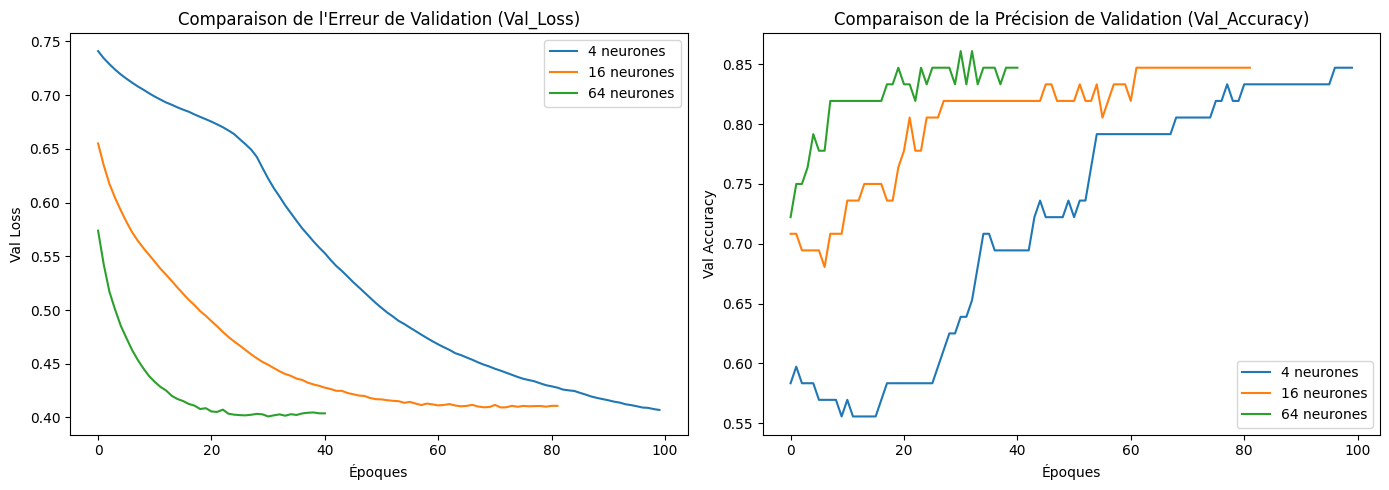

In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

titanic = sns.load_dataset("titanic")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# valeurs manquantes : on utilise les statistiques du train
fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# variables catégorielles (mêmes colonnes pour train et test)
cat = ["sex", "embarked", "pclass"]
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# normalisation des colonnes numériques (fit sur le train)
num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

# conversion en tableaux numpy et vérification des dimensions
X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
print("Shape X_train:", X_train.shape, "| Shape X_test:", X_test.shape)

# Test avec 4, 16 et 64 neurones cachés

tailles_couche_cachee = [4, 16, 64]

plt.figure(figsize=(14, 5))

for nb_neurones in tailles_couche_cachee:
    print(f"\n--- Entraînement avec {nb_neurones} neurones cachés ---")

    # On reprend la structure de ton cours en modifiant uniquement le nombre de neurones
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(nb_neurones, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    early = EarlyStopping(patience=10, restore_best_weights=True)
    history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                        validation_split=0.1, callbacks=[early], verbose=0)

    # Affichage du rapport pour les 16 neurones (ou pour tous si tu veux)
    if nb_neurones == 16:
        pred = (model.predict(X_test) > 0.5).astype(int).ravel()
        print("Rapport de classification pour 16 neurones :")
        print(classification_report(y_test, pred))

    # Superposition des courbes de validation (Val Loss et Val Accuracy)
    plt.subplot(1, 2, 1)
    plt.plot(history.history['val_loss'], label=f'{nb_neurones} neurones')
    plt.title("Comparaison de l'Erreur de Validation (Val_Loss)")
    plt.xlabel('Époques')
    plt.ylabel('Val Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['val_accuracy'], label=f'{nb_neurones} neurones')
    plt.title("Comparaison de la Précision de Validation (Val_Accuracy)")
    plt.xlabel('Époques')
    plt.ylabel('Val Accuracy')
    plt.legend()

plt.tight_layout()
plt.show()